# Detección de ataques en una infraestructura de red

## Introducción

Las infraestructuras de red están expuestas de forma continua a ataques (denegación de servicio, escaneo de puertos, acceso no autorizado, escalada de privilegios, etc.). Detectarlos de forma manual es inviable por el volumen de tráfico, por lo que los **sistemas de detección de intrusiones (IDS)** se apoyan cada vez más en técnicas de aprendizaje automático.

El objetivo de este trabajo es construir un modelo capaz de **distinguir el tráfico de red normal del tráfico anómalo (ataque)** a partir de las características de cada conexión. Para ello se emplea el conjunto de datos NSL-KDD y se comparan **dos algoritmos de clasificación supervisada**: regresión logística y árbol de decisión.

El trabajo sigue el flujo habitual de un proyecto de aprendizaje automático:

0. **Imports**: instalación y carga de las librerías necesarias.
1. **Lectura del conjunto de datos**: carga de los ficheros ARFF y definición de funciones auxiliares para convertirlos a `DataFrame`, separar características y etiqueta y evaluar modelos.
2. **Visualización y análisis exploratorio**: primera inspección del conjunto de entrenamiento (dimensiones, tipos, estadísticos, variables categóricas y balance de clases) para ganar intuiciones.
3. **Preprocesamiento**: comprobación de valores nulos, codificación de variables categóricas, selección de características por correlación, división en entrenamiento/prueba y escalado.
4. **Selección y entrenamiento de los modelos**: ajuste de una regresión logística y un árbol de decisión.
5. **Métricas y comparación de resultados**: evaluación con F1-score y matriz de confusión, y análisis de las diferencias entre ambos modelos.

### Dataset

#### Abstract
NSL-KDD is a data set suggested to solve some of the inherent problems of the KDD'99 data set which are mentioned in [1]. Although, this new version of the KDD data set still suffers from some of the problems discussed by McHugh [2] and may not be a perfect representative of existing real networks, because of the lack of public data sets for network-based IDSs, we believe it still can be applied as an effective benchmark data set to help researchers compare different intrusion detection methods. Furthermore, the number of records in the NSL-KDD train and test sets are reasonable. This advantage makes it affordable to run the experiments on the complete set without the need to randomly select a small portion. Consequently, evaluation results of different research work will be consistent and comparable.

#### Data Files
* KDDTrain+.ARFF: The full NSL-KDD train set with binary labels in ARFF format
* **KDDTrain+.TXT**: The full NSL-KDD train set including attack-type labels and difficulty level in CSV format
* KDDTrain+_20Percent.ARFF:	A 20% subset of the KDDTrain+.arff file
* KDDTrain+_20Percent.TXT:	A 20% subset of the KDDTrain+.txt file
* KDDTest+.ARFF:	The full NSL-KDD test set with binary labels in ARFF format
* **KDDTest+.TXT**:	The full NSL-KDD test set including attack-type labels and difficulty level in CSV format
* KDDTest-21.ARFF:	A subset of the KDDTest+.arff file which does not include records with difficulty level of 21 out of 21
* KDDTest-21.TXT:	A subset of the KDDTest+.txt file which does not include records with difficulty level of 21 out of 21

## 0. Imports

In [1]:
# Instalamos un nuevo paquete en el kernel de jupyter notebook actual para parsear ficheros arff
import sys

!{sys.executable} -m pip install liac-arff

In [2]:
import pandas as pd
from sklearn.preprocessing import OneHotEncoder, RobustScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import f1_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import seaborn as sns
import arff

## 1. Lectura del conjunto de datos

En este apartado se carga el conjunto de datos de entrenamiento a partir del fichero ARFF y se preparan las estructuras necesarias para el resto del trabajo:
* Los datos se almacenan en un `DataFrame` de `pandas`.
* Se separan las características de entrada (`X`) del valor de salida o etiqueta (`y`, la columna `class`).
* Más adelante, tras el preprocesamiento, los datos se dividen en subconjuntos de entrenamiento y prueba.

### Formato de los ficheros ARFF

An **ARFF (Attribute-Relation File Format)** file is an ASCII text file that describes a list of instances sharing a set of attributes. ARFF files were developed by the Machine Learning Project at the Department of Computer Science of The University of Waikato for use with the Weka machine learning software. Más información: https://www.cs.waikato.ac.nz/ml/weka/arff.html

### Funciones auxiliares

Se definen cuatro funciones reutilizables: `load_kdd_data` lee un fichero ARFF, `get_df_from_dict` lo convierte en un `DataFrame` con los nombres de atributo como columnas, `remove_label` separa la etiqueta de las características y `evaluate_classifier` muestra la métrica y la matriz de confusión de un clasificador.

In [3]:
TRAIN_FILE = "NSL-KDD/KDDTrain+.arff"

In [4]:
# Lectura del conjunto de datos que se encuentra en formato .arff
def load_kdd_data(file: str) -> dict:
    with open(file, 'r') as data_set:
        data_dict = arff.load(data_set)

    return data_dict

In [5]:
def get_df_from_dict(df: dict) -> pd.DataFrame:
    # Obtención de los nombres de los atributos
    column_names = [value[0] for value in df['attributes']]
    return pd.DataFrame.from_records(df['data'], columns=column_names)

In [6]:
def remove_label(df: pd.DataFrame, label_name: str):
    X = df.drop(label_name, axis=1)
    y = df[label_name].copy()
    return X, y

In [7]:
def evaluate_classifier(y_pred, y_test, clf, metric, labels = ["normal", "anomaly"]):
    print(f"{metric.__name__}:", metric(y_pred, y_test))
    print("Matriz de confusión")
    cm = confusion_matrix(y_test, y_pred, labels=clf.classes_)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
    disp.plot()

## 2. Visualización del conjunto de datos para ganar intuiciones

El proceso de visualización se realiza siempre sobre el conjunto de entrenamiento, apartando el de prueba. Esto evita que se generen intuiciones a partir de los datos de prueba que acaben incorporándose al modelo.

Una buena práctica es trabajar sobre una copia del conjunto de entrenamiento, de modo que las transformaciones que se prueben no dañen el original.

En este apartado se analizan los valores de las características de entrada:
* Columnas y filas del conjunto de datos.
* Información general: tipos de datos y valores no nulos.
* Valores distintos de las columnas categóricas.
* Distribución general de los atributos mediante estadísticos descriptivos.

In [8]:
# Lectura de los datos de entranamiento
df_dict = load_kdd_data(TRAIN_FILE)

In [9]:
# Creación de los dataframe de entrenamiento
df = get_df_from_dict(df_dict)

In [10]:
df.head(10)

,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,class
0,0.0,tcp,ftp_data,SF,491.0,0.0,0,0.0,0.0,0.0,...,25.0,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal
1,0.0,udp,other,SF,146.0,0.0,0,0.0,0.0,0.0,...,1.0,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal
2,0.0,tcp,private,S0,0.0,0.0,0,0.0,0.0,0.0,...,26.0,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,anomaly
3,0.0,tcp,http,SF,232.0,8153.0,0,0.0,0.0,0.0,...,255.0,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal
4,0.0,tcp,http,SF,199.0,420.0,0,0.0,0.0,0.0,...,255.0,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal
5,0.0,tcp,private,REJ,0.0,0.0,0,0.0,0.0,0.0,...,19.0,0.07,0.07,0.00,0.00,0.00,0.00,1.00,1.00,anomaly
6,0.0,tcp,private,S0,0.0,0.0,0,0.0,0.0,0.0,...,9.0,0.04,0.05,0.00,0.00,1.00,1.00,0.00,0.00,anomaly
7,0.0,tcp,private,S0,0.0,0.0,0,0.0,0.0,0.0,...,15.0,0.06,0.07,0.00,0.00,1.00,1.00,0.00,0.00,anomaly
8,0.0,tcp,remote_job,S0,0.0,0.0,0,0.0,0.0,0.0,...,23.0,0.09,0.05,0.00,0.00,1.00,1.00,0.00,0.00,anomaly
9,0.0,tcp,private,S0,0.0,0.0,0,0.0,0.0,0.0,...,13.0,0.05,0.06,0.00,0.00,1.00,1.00,0.00,0.00,anomaly


Observando la forma del conjunto de datos podemos apreciar como este cuenta con 125973 ejemplos y 42 características

In [11]:
df.shape

(125973, 42)

In [12]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 125973 entries, 0 to 125972
Data columns (total 42 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   duration                     125973 non-null  float64
 1   protocol_type                125973 non-null  str    
 2   service                      125973 non-null  str    
 3   flag                         125973 non-null  str    
 4   src_bytes                    125973 non-null  float64
 5   dst_bytes                    125973 non-null  float64
 6   land                         125973 non-null  str    
 7   wrong_fragment               125973 non-null  float64
 8   urgent                       125973 non-null  float64
 9   hot                          125973 non-null  float64
 10  num_failed_logins            125973 non-null  float64
 11  logged_in                    125973 non-null  str    
 12  num_compromised              125973 non-null  float64
 13  root_shell

Analizando más a fondo el conjunto de datos podemos ver como por lo general la mayoría de valores son númericos con ciertos decimales y como su tipo de datos se adecúa al mismo. Sin embargo, hay ciertas características categóricas, como el tipo de protocolo o servicio, que tienen un tipo `object` y que en fases posteriores habrá que adaptar para poder trabajar con las ellas.

Por lo demás el conjunto de datos está bastante limpio ya que las variables tienen un nombre adecuado con el que poder trabajar y parece ser que no hay ningún valor nulo que pueda causar problemas posteriores.

Si bien todavía hay que realizar cierto preprocesamiento de los datos, resulta de interés tener una primera visión de los mismos calculando algúnas medidas estadísticas típicas que nos indiquen la distribución de nuestros datos.

In [13]:
df.describe()

,duration,src_bytes,dst_bytes,wrong_fragment,urgent,hot,num_failed_logins,num_compromised,root_shell,su_attempted,...,dst_host_count,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate
count,125973.00000,1.259730e+05,1.259730e+05,125973.000000,125973.000000,125973.000000,125973.000000,125973.000000,125973.000000,125973.000000,...,125973.000000,125973.000000,125973.000000,125973.000000,125973.000000,125973.000000,125973.000000,125973.000000,125973.000000,125973.000000
mean,287.14465,4.556674e+04,1.977911e+04,0.022687,0.000111,0.204409,0.001222,0.279250,0.001342,0.001103,...,182.148945,115.653005,0.521242,0.082951,0.148379,0.032542,0.284452,0.278485,0.118832,0.120240
std,2604.51531,5.870331e+06,4.021269e+06,0.253530,0.014366,2.149968,0.045239,23.942042,0.036603,0.045154,...,99.206213,110.702741,0.448949,0.188922,0.308997,0.112564,0.444784,0.445669,0.306557,0.319459
min,0.00000,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.00000,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,82.000000,10.000000,0.050000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.00000,4.400000e+01,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,255.000000,63.000000,0.510000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,0.00000,2.760000e+02,5.160000e+02,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,255.000000,255.000000,1.000000,0.070000,0.060000,0.020000,1.000000,1.000000,0.000000,0.000000
max,42908.00000,1.379964e+09,1.309937e+09,3.000000,3.000000,77.000000,5.000000,7479.000000,1.000000,2.000000,...,255.000000,255.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


Simplemente realizando estos pequeños cálculos ya se pueden detectar cieras características que tienen un amplio rango de valores y que pueden ser susceptibles de ser escaladas como la duración o los bytes de origen y destino.

### Variables categóricas

A continuación se analizarán las distintas variables categóricas del conjunto de datos observando los distintos valores que estas pueden tomar y el número de ejemplos de cada una.

In [14]:
df['protocol_type'].value_counts()

protocol_type
tcp     102689
udp      14993
icmp      8291
Name: count, dtype: int64

In [15]:
df['service'].value_counts()

service
http         40338
private      21853
domain_u      9043
smtp          7313
ftp_data      6860
             ...  
tftp_u           3
http_8001        2
aol              2
harvest          2
http_2784        1
Name: count, Length: 70, dtype: int64

In [16]:
df['service'].unique()

<StringArray>
[   'ftp_data',       'other',     'private',        'http',  'remote_job',
        'name',  'netbios_ns',       'eco_i',         'mtp',      'telnet',
      'finger',    'domain_u',      'supdup',   'uucp_path',      'Z39_50',
        'smtp',    'csnet_ns',        'uucp', 'netbios_dgm',       'urp_i',
        'auth',      'domain',         'ftp',         'bgp',        'ldap',
       'ecr_i',      'gopher',       'vmnet',      'systat',    'http_443',
         'efs',       'whois',       'imap4',    'iso_tsap',        'echo',
      'klogin',        'link',      'sunrpc',       'login',      'kshell',
     'sql_net',        'time',   'hostnames',        'exec',       'ntp_u',
     'discard',        'nntp',     'courier',         'ctf',         'ssh',
     'daytime',       'shell',     'netstat',       'pop_3',        'nnsp',
         'IRC',       'pop_2',     'printer',       'tim_i',     'pm_dump',
       'red_i', 'netbios_ssn',         'rje',         'X11',       'urh_i'

In [17]:
df['flag'].value_counts()

flag
SF        74945
S0        34851
REJ       11233
RSTR       2421
RSTO       1562
S1          365
SH          271
S2          127
RSTOS0      103
S3           49
OTH          46
Name: count, dtype: int64

In [18]:
df['land'].value_counts()

land
0    125948
1        25
Name: count, dtype: int64

In [19]:
df['logged_in'].value_counts()

logged_in
0    76121
1    49852
Name: count, dtype: int64

In [20]:
df['is_host_login'].value_counts()

is_host_login
0    125972
1         1
Name: count, dtype: int64

In [21]:
df['is_guest_login'].value_counts()

is_guest_login
0    124786
1      1187
Name: count, dtype: int64

Como se puede apreciar la mayoría de los datos provienen de tráfico tcp a través de servicios http, dns, smtp, ftp, etc.

También se ha detectado que muchas de las variables que tenían un tipo `object` realmente sólo toman dos valores, 0 y 1, por lo que pueden ser tratadas como números directamente sin emplear ningún tipo de tratamiento adicional como se verá más adelante.

En cuanto a la clasificación del tráfico podemos ver como hay un número similar de ejemplos de tráfico normal y anómalo siendo algo superior el primero.

In [22]:
df['class'].value_counts()

class
normal     67343
anomaly    58630
Name: count, dtype: int64

## 3. Preprocesamiento del conjunto de datos

###     3.1. Limpiando el conjunto de datos

La mayoría de los algoritmos de aprendizaje automático no pueden trabajar con características que contengan valores nulos. En este paso se comprueba si el conjunto de datos los contiene y, en caso afirmativo, se aplicaría alguna técnica para tratarlos: eliminar las filas o la columna afectadas, o rellenarlos con un valor determinado (cero, media, etc.).

En este caso, como se ha podido comprobar en el análisis exploratorio anterior, el conjunto de datos no tiene valores nulos. No obstante se emplean las siguientes funciones de `pandas` para comprobarlo de manera definitiva.

In [23]:
df.isna().any()

duration                       False
protocol_type                  False
service                        False
flag                           False
src_bytes                      False
dst_bytes                      False
land                           False
wrong_fragment                 False
urgent                         False
hot                            False
num_failed_logins              False
logged_in                      False
num_compromised                False
root_shell                     False
su_attempted                   False
num_root                       False
num_file_creations             False
num_shells                     False
num_access_files               False
num_outbound_cmds              False
is_host_login                  False
is_guest_login                 False
count                          False
srv_count                      False
serror_rate                    False
srv_serror_rate                False
rerror_rate                    False
s

### 3.2. Transformación de los atributos categóricos

Los algoritmos de aprendizaje automático, por norma general, ingieren datos numéricos. En este paso se identifican las variables categóricas del conjunto de datos y se transforman a valores numéricos, justificando la técnica elegida.

Tal y como se pudo observar en el análisis exploratorio de los datos, existen varias características categóricas como el protocolo o el servicio. Estas variables no son adecuadas para los algoritmos de Machine Learning ya que estos sólo trabajan con datos numéricos, por lo que será necesario aplicar una conversión.

Para realizar esta conversión se pueden utilizar distintas técnicas como el `LabelEncoding`, `One-Hot Encoding` o `CountVectorizer` por nombrar algunas. Sin embargo, se evitará utilizar la primera ya que esta sustituye cada categoría por un valor númerico como 0, 1, 2, etc. Esto quiere decir que si por ejemplo las categorías son `tcp`, `udp`, `icmp` dicho algoritmo las susituiría por `tcp = 0` , `udp = 1`, `icmp = 2`, lo cual podría transmitir un sesgo de proximidad al algoritmo de aprendizaje automático el cual creería que dichos valores tienen cierta relación de proximidad.

En su lugar se utilizará el `One-Hot Enconding` que no transmite dicho sesgo, pues lo que hace es crear un vector con tantas posiciones como valores pueda tomar la variable categórica y en caso de que para un ejemplo de los datos aparezca un valor se marcará como un 1 en la posición correspondiente. Además previene problemas con los algoritmos sobre la interpretación de valores categóricos como si fueran ordinales.

A parte de lo anterior, la decisión de utilizar está técnica frente a otras como `CountVectorizer` es que para este caso en concreto realmente no nos interesa tanto saber cuantas veces aparece un valor para dicho ejemplo sino si aparece o no, por ejemplo si dicho ejemplo corresponde a tráfico `tcp`, `udp` o `icmp`. Además ahorraríamos espacio en la representación.

La técnica de `CountVectorizer` tendría sentido para rangos de valores más grandes y cuando la frecuencia de aparición de un valor es relevante para el problema, por ejemplo, en problemas relacionados con procesamiento del lenguaje natural donde es interesante conocer las veces que aparece una palabra en un texto.

Las columnas que se transformarán son `protocol_type`, `service` y `flag` ya que son las que realmente son categóricas pues el resto de columnas como `is_host_login` son realmente booleanas y están representadas de manera númerica con 0 y 1.

In [24]:
enc = OneHotEncoder()
categorical_features = enc.fit_transform(df[['protocol_type', 'service', 'flag']])
categorical_features.toarray()

array([[0., 1., 0., ..., 0., 1., 0.],
       [0., 0., 1., ..., 0., 1., 0.],
       [0., 1., 0., ..., 0., 0., 0.],
       ...,
       [0., 1., 0., ..., 0., 1., 0.],
       [0., 1., 0., ..., 0., 0., 0.],
       [0., 1., 0., ..., 0., 1., 0.]], shape=(125973, 84))

In [25]:
enc.get_feature_names_out()

array(['protocol_type_icmp', 'protocol_type_tcp', 'protocol_type_udp',
       'service_IRC', 'service_X11', 'service_Z39_50', 'service_aol',
       'service_auth', 'service_bgp', 'service_courier',
       'service_csnet_ns', 'service_ctf', 'service_daytime',
       'service_discard', 'service_domain', 'service_domain_u',
       'service_echo', 'service_eco_i', 'service_ecr_i', 'service_efs',
       'service_exec', 'service_finger', 'service_ftp',
       'service_ftp_data', 'service_gopher', 'service_harvest',
       'service_hostnames', 'service_http', 'service_http_2784',
       'service_http_443', 'service_http_8001', 'service_imap4',
       'service_iso_tsap', 'service_klogin', 'service_kshell',
       'service_ldap', 'service_link', 'service_login', 'service_mtp',
       'service_name', 'service_netbios_dgm', 'service_netbios_ns',
       'service_netbios_ssn', 'service_netstat', 'service_nnsp',
       'service_nntp', 'service_ntp_u', 'service_other',
       'service_pm_dump', 'serv

In [26]:
df_categorical = pd.DataFrame(categorical_features.toarray(), columns=enc.get_feature_names_out())
df_categorical

,protocol_type_icmp,protocol_type_tcp,protocol_type_udp,service_IRC,service_X11,service_Z39_50,service_aol,service_auth,service_bgp,service_courier,...,flag_REJ,flag_RSTO,flag_RSTOS0,flag_RSTR,flag_S0,flag_S1,flag_S2,flag_S3,flag_SF,flag_SH
0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
3,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
125968,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
125969,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
125970,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
125971,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0


In [27]:
# Codificación de la clase como númerica (0 = normal, 1 = anomalía)
df_copy = df.copy()
df_copy['class'] = df['class'].factorize()[0]
df_copy[['class']]

,class
0,0
1,0
2,1
3,0
4,0
...,...
125968,1
125969,0
125970,0
125971,1


In [28]:
# Nos deshacemos de las variables categóricas y nos quedamos con las transformaciones codificadas
df_copy_clean = df_copy.drop(['protocol_type', 'service', 'flag'], axis=1)
X = pd.concat([df_copy_clean, df_categorical], axis=1)
X

,duration,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,num_failed_logins,logged_in,num_compromised,...,flag_REJ,flag_RSTO,flag_RSTOS0,flag_RSTR,flag_S0,flag_S1,flag_S2,flag_S3,flag_SF,flag_SH
0,0.0,491.0,0.0,0,0.0,0.0,0.0,0.0,0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1,0.0,146.0,0.0,0,0.0,0.0,0.0,0.0,0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2,0.0,0.0,0.0,0,0.0,0.0,0.0,0.0,0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
3,0.0,232.0,8153.0,0,0.0,0.0,0.0,0.0,1,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,0.0,199.0,420.0,0,0.0,0.0,0.0,0.0,1,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
125968,0.0,0.0,0.0,0,0.0,0.0,0.0,0.0,0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
125969,8.0,105.0,145.0,0,0.0,0.0,0.0,0.0,0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
125970,0.0,2231.0,384.0,0,0.0,0.0,0.0,0.0,1,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
125971,0.0,0.0,0.0,0,0.0,0.0,0.0,0.0,0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0


#### Correlación

Una vez contamos con el dataframe con todas las variables codificadas, en este apartado se estudiará la correlación de las distintas características con la clase/etiqueta. De esta manera podremos conocer qué variables son realmente significativas para el problema, es decir, aquellas que cuando cambian la clase lo hace también. Esto es de especial relevancia en este caso práctico ya que el número de características es bastante elevado, por lo que preservaremos sólo aquellas variables que tengan una buena relación tanto positiva como negativa con la etiqueta.

In [29]:
corr_matrix = X.corr()
corr_matrix['class'].sort_values(ascending=False)

class                       1.000000
dst_host_srv_serror_rate    0.654985
dst_host_serror_rate        0.651842
serror_rate                 0.650652
flag_S0                     0.650206
                              ...   
dst_host_same_srv_rate     -0.693803
dst_host_srv_count         -0.722535
same_srv_rate              -0.751913
flag_SF                    -0.756286
num_outbound_cmds                NaN
Name: class, Length: 123, dtype: float64

In [30]:
corr_matrix

,duration,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,num_failed_logins,logged_in,num_compromised,...,flag_REJ,flag_RSTO,flag_RSTOS0,flag_RSTR,flag_S0,flag_S1,flag_S2,flag_S3,flag_SF,flag_SH
duration,1.000000,0.070737,0.034878,-0.001553,-0.009866,0.003830,0.000705,0.009528,-0.064218,0.042679,...,-0.034493,-0.005336,0.034268,0.539954,-0.068182,-0.005943,-0.003411,0.001148,-0.068255,-0.005119
src_bytes,0.070737,1.000000,0.000204,-0.000109,-0.000693,-0.000059,0.000295,-0.000208,-0.003353,-0.000086,...,-0.002429,0.007609,0.178046,-0.000685,-0.004800,0.000007,-0.000229,0.000682,-0.006079,-0.000360
dst_bytes,0.034878,0.000204,1.000000,-0.000069,-0.000440,0.000248,-0.000344,0.000504,-0.002894,0.001233,...,-0.001539,-0.000537,-0.000141,0.029685,-0.003042,0.000147,0.000215,-0.000077,-0.004509,-0.000228
land,-0.001553,-0.000109,-0.000069,1.000000,-0.001261,-0.000109,-0.001340,-0.000381,-0.011402,-0.000164,...,-0.004408,-0.001579,-0.000403,-0.001972,0.022781,-0.000759,-0.000448,-0.000278,-0.017074,-0.000654
wrong_fragment,-0.009866,-0.000693,-0.000440,-0.001261,1.000000,-0.000692,-0.008508,-0.002418,-0.072418,-0.001044,...,-0.027999,-0.010027,-0.002560,-0.012526,-0.055342,-0.004824,-0.002843,-0.001765,0.073840,-0.004155
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
flag_S1,-0.005943,0.000007,0.000147,-0.000759,-0.004824,-0.000417,-0.000797,0.001808,0.052719,0.016717,...,-0.016867,-0.006040,-0.001542,-0.007546,-0.033338,1.000000,-0.001712,-0.001063,-0.065329,-0.002503
flag_S2,-0.003411,-0.000229,0.000215,-0.000448,-0.002843,-0.000246,0.008963,-0.000858,0.033628,-0.000360,...,-0.009940,-0.003560,-0.000909,-0.004447,-0.019646,-0.001712,1.000000,-0.000627,-0.038499,-0.001475
flag_S3,0.001148,0.000682,-0.000077,-0.000278,-0.001765,-0.000153,-0.000190,0.017265,0.019436,-0.000129,...,-0.006172,-0.002210,-0.000564,-0.002761,-0.012199,-0.001063,-0.000627,1.000000,-0.023906,-0.000916
flag_SF,-0.068255,-0.006079,-0.004509,-0.017074,0.073840,0.006383,0.074924,0.000136,0.641738,0.007291,...,-0.379191,-0.135793,-0.034668,-0.169644,-0.749485,-0.065329,-0.038499,-0.023906,1.000000,-0.056270


In [31]:
pos_corr = corr_matrix[corr_matrix['class'] > 0.5]
pos_corr

,duration,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,num_failed_logins,logged_in,num_compromised,...,flag_REJ,flag_RSTO,flag_RSTOS0,flag_RSTR,flag_S0,flag_S1,flag_S2,flag_S3,flag_SF,flag_SH
count,-0.079042,-0.005152,-0.003543,-0.009837,-0.020819,-0.005615,-0.068697,-0.019544,-0.539754,-0.008434,...,0.199033,0.064743,0.010327,-0.083113,0.461591,-0.038381,-0.021662,-0.013410,-0.518345,-0.032903
serror_rate,-0.069873,-0.003228,-0.003059,0.021734,-0.043316,-0.004929,-0.059083,-0.015254,-0.491925,-0.005297,...,-0.189105,-0.071002,0.018269,-0.089166,0.979174,0.058044,0.037466,0.014392,-0.758419,0.073167
srv_serror_rate,-0.069510,-0.003438,-0.003038,0.022614,-0.056549,-0.004889,-0.058713,-0.015899,-0.490167,-0.005278,...,-0.196510,-0.070592,0.012845,-0.088459,0.982660,0.052419,0.024159,0.012967,-0.755827,0.074022
dst_host_serror_rate,-0.064948,-0.004503,-0.003024,0.019840,-0.051917,-0.004749,-0.058222,-0.011648,-0.491478,-0.004377,...,-0.189188,-0.069490,0.001325,-0.086924,0.975844,-0.019868,-0.011914,-0.008307,-0.741814,0.063607
dst_host_srv_serror_rate,-0.064361,-0.003397,-0.002944,0.012276,-0.055917,-0.004834,-0.058214,-0.012299,-0.493264,-0.004898,...,-0.195173,-0.068584,0.012729,-0.086059,0.981209,-0.013145,-0.016595,-0.008216,-0.745691,0.073571
class,0.048785,0.005921,0.004118,0.007191,0.095905,-0.002787,-0.013083,-0.003755,-0.690171,-0.010198,...,0.184949,0.088592,0.030658,0.133099,0.650206,-0.049114,-0.025629,-0.015178,-0.756286,0.049075
flag_S0,-0.068182,-0.004800,-0.003042,0.022781,-0.055342,-0.004784,-0.058741,-0.016712,-0.500442,-0.007213,...,-0.193502,-0.069296,-0.017691,-0.086570,1.000000,-0.033338,-0.019646,-0.012199,-0.749485,-0.028715


In [32]:
neg_corr = corr_matrix[corr_matrix['class'] < -0.5]
neg_corr

,duration,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,num_failed_logins,logged_in,num_compromised,...,flag_REJ,flag_RSTO,flag_RSTOS0,flag_RSTR,flag_S0,flag_S1,flag_S2,flag_S3,flag_SF,flag_SH
logged_in,-0.064218,-0.003353,-0.002894,-0.011402,-0.072418,0.007299,0.116435,-0.006439,1.000000,0.014413,...,-0.253209,-0.070580,-0.023150,-0.093418,-0.500442,0.052719,0.033628,0.019436,0.641738,-0.037575
same_srv_rate,0.074681,0.003899,0.003788,0.008739,0.054759,0.005967,0.069365,0.019477,0.600536,0.008944,...,-0.235683,-0.107222,-0.034402,0.085027,-0.765292,0.036971,0.022795,0.013850,0.826883,0.032460
dst_host_srv_count,-0.109776,-0.006861,-0.004224,-0.014159,-0.045240,-0.007897,-0.051864,-0.023053,0.624365,-0.010321,...,-0.181486,-0.091482,-0.028413,-0.133366,-0.552879,0.012040,0.024130,0.001964,0.670869,-0.047963
dst_host_same_srv_rate,-0.116005,-0.006572,-0.004424,0.011597,-0.048733,-0.004489,-0.036293,-0.001576,0.604058,-0.004995,...,-0.182978,-0.095359,-0.031579,-0.141390,-0.617256,0.013592,0.024946,0.005810,0.733630,-0.050249
service_http,-0.075233,-0.005152,-0.002607,-0.009670,-0.061417,-0.005309,-0.046956,-0.018547,0.699557,-0.007326,...,-0.046982,-0.064449,-0.018443,-0.083681,-0.371888,0.017449,0.027521,0.001130,0.404777,-0.031500
flag_SF,-0.068255,-0.006079,-0.004509,-0.017074,0.073840,0.006383,0.074924,0.000136,0.641738,0.007291,...,-0.379191,-0.135793,-0.034668,-0.169644,-0.749485,-0.065329,-0.038499,-0.023906,1.000000,-0.056270


In [33]:
features = list(pos_corr.index) + list(neg_corr.index)
features.remove('class')
print("Número de características significativas: ", len(features))
print(features)

Número de características significativas:  12
['count', 'serror_rate', 'srv_serror_rate', 'dst_host_serror_rate', 'dst_host_srv_serror_rate', 'flag_S0', 'logged_in', 'same_srv_rate', 'dst_host_srv_count', 'dst_host_same_srv_rate', 'service_http', 'flag_SF']


#### Train/Test Split

In [34]:
# Separamos las etiquetas de las características en el conjunto de entrenamiento
X, y = remove_label(X, 'class')

In [35]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [36]:
X_train_feat_select = X_train[features]
X_train_feat_select

,count,serror_rate,srv_serror_rate,dst_host_serror_rate,dst_host_srv_serror_rate,flag_S0,logged_in,same_srv_rate,dst_host_srv_count,dst_host_same_srv_rate,service_http,flag_SF
95141,16.0,0.0,0.0,0.0,0.0,0.0,1,1.00,255.0,1.00,1.0,1.0
37486,142.0,1.0,1.0,1.0,1.0,1.0,0,0.01,2.0,0.01,0.0,0.0
34926,273.0,0.0,0.0,0.0,0.0,0.0,0,0.03,8.0,0.03,1.0,0.0
34589,20.0,0.0,0.0,0.0,0.0,0.0,1,1.00,255.0,1.00,1.0,1.0
11420,274.0,0.0,0.0,0.0,0.0,0.0,0,1.00,255.0,1.00,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...
119879,258.0,0.0,0.0,0.0,0.0,0.0,0,0.02,4.0,0.02,0.0,0.0
103694,24.0,1.0,1.0,1.0,1.0,1.0,0,0.17,4.0,0.02,0.0,0.0
860,258.0,0.0,0.0,0.0,0.0,0.0,0,0.02,6.0,0.02,1.0,0.0
15795,5.0,0.0,0.0,0.0,0.0,0.0,1,1.00,255.0,1.00,1.0,1.0


In [37]:
X_test_feat_select = X_test[features]
X_test_feat_select

,count,serror_rate,srv_serror_rate,dst_host_serror_rate,dst_host_srv_serror_rate,flag_S0,logged_in,same_srv_rate,dst_host_srv_count,dst_host_same_srv_rate,service_http,flag_SF
378,2.0,0.0,0.0,0.00,0.00,0.0,0,1.00,171.0,1.00,0.0,1.0
32038,42.0,1.0,1.0,1.00,1.00,1.0,0,0.26,44.0,0.17,1.0,0.0
86399,284.0,1.0,1.0,1.00,1.00,1.0,0,0.07,20.0,0.08,0.0,0.0
74412,110.0,0.0,0.0,0.00,0.00,0.0,0,0.07,27.0,0.11,0.0,0.0
52951,1.0,0.0,0.0,0.04,0.00,0.0,0,1.00,1.0,0.01,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...
114267,11.0,0.0,0.0,0.00,0.00,0.0,1,1.00,255.0,1.00,1.0,1.0
69047,1.0,0.0,0.0,0.00,0.00,0.0,0,1.00,129.0,1.00,0.0,1.0
56135,2.0,0.0,0.0,0.00,0.00,0.0,0,1.00,9.0,0.06,0.0,1.0
103927,1.0,0.0,0.0,0.02,0.02,0.0,1,1.00,141.0,0.55,0.0,1.0


### 3.3. Escalado del conjunto de datos

Si los valores del conjunto de datos se encuentran en rangos muy diferentes, es conveniente aplicar técnicas de normalización o escalado para que ciertos algoritmos (como la regresión logística) funcionen mejor. En este paso se comprueba si existen valores muy dispares y se justifica la técnica de escalado utilizada.

Tal y como se comentó en el análisis exploratorio, observando distintas medidas como la media y valores máximos y mínimos de las variables destacan algunas de estas ya que cuentan con un rango de valores muy dispar (4 mil a 200, miles de millones a 0, etc).

Para asegurar el correcto funcionamiento de los algoritmos de Machine Learning se emplearán técnicas de escalado para disminuir la diferencia entre los valores conservando la distribución pero acotando el rango.

La técnica de escalado que se utilizará será `RobustScaler`, ya que está técnica es robusta frente a los **outliers** mientras que otras como `Min-Max Scaling` no lo son. Esto es especialmente relevante en nuestros datos ya que al comparar la media y deviación estándar (como se vió en el análisis exploratorio) con los valores máximos que algunas columnas pueden alcanzar, la diferencia es muy grande lo cual puede indicar ciertos valores anómalamente grandes.

In [38]:
scaler = RobustScaler()
X_train_scaled = scaler.fit_transform(X_train_feat_select)
X_train_scaled = pd.DataFrame(X_train_scaled, columns=X_train_feat_select.columns, index=X_train_feat_select.index)
X_train_scaled

,count,serror_rate,srv_serror_rate,dst_host_serror_rate,dst_host_srv_serror_rate,flag_S0,logged_in,same_srv_rate,dst_host_srv_count,dst_host_same_srv_rate,service_http,flag_SF
95141,0.014184,0.0,0.0,0.0,0.0,0.0,1.0,0.000000,0.786885,0.515789,1.0,0.0
37486,0.907801,1.0,1.0,1.0,1.0,1.0,0.0,-1.087912,-0.250000,-0.526316,0.0,-1.0
34926,1.836879,0.0,0.0,0.0,0.0,0.0,0.0,-1.065934,-0.225410,-0.505263,1.0,-1.0
34589,0.042553,0.0,0.0,0.0,0.0,0.0,1.0,0.000000,0.786885,0.515789,1.0,0.0
11420,1.843972,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.786885,0.515789,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...
119879,1.730496,0.0,0.0,0.0,0.0,0.0,0.0,-1.076923,-0.241803,-0.515789,0.0,-1.0
103694,0.070922,1.0,1.0,1.0,1.0,1.0,0.0,-0.912088,-0.241803,-0.515789,0.0,-1.0
860,1.730496,0.0,0.0,0.0,0.0,0.0,0.0,-1.076923,-0.233607,-0.515789,1.0,-1.0
15795,-0.063830,0.0,0.0,0.0,0.0,0.0,1.0,0.000000,0.786885,0.515789,1.0,0.0


In [39]:
X_test_scaled = scaler.transform(X_test_feat_select)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X_test_feat_select.columns, index=X_test_feat_select.index)

## 4. Selección y entrenamiento de los modelos

Llegados a este punto, los datos ya han sido transformados para poder ser ingeridos por un algoritmo de aprendizaje automático. En este apartado se entrenan **dos** algoritmos de clasificación basados en aprendizaje supervisado.

En este caso se han seleccionado los algoritmos de regresión lógistica y árbol de decisión para comparar como se comportan dos algoritmos distintos frente a este problema en vez de utilizar sólo algoritmos basados en árboles de decisión como `Random Forest`.

### Regresión Logística

In [40]:
clf = LogisticRegression(max_iter=1000)
clf.fit(X_train_scaled, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [41]:
y_lr_train_pred = clf.predict(X_train_scaled)

In [42]:
y_lr_test_pred = clf.predict(X_test_scaled)

### Árboles

Aunque se generó una copia del conjunto de datos de entrenamiento escalado y con características reducidas, en el caso de los árboles de decisión no se empleará, ya que debido al funcionamiento de estos algoritmos el desempeño cuando las variables están escaladas suele ser peor que cuando no lo están y no requieren tanto de selección de características, por lo que se utilizará la división original.

In [43]:
MAX_DEPTH = 50

clf_tree = DecisionTreeClassifier(max_depth=MAX_DEPTH, random_state=42)
clf_tree.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",50
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples i

In [44]:
y_tree_train_pred = clf_tree.predict(X_train)

In [45]:
y_tree_test_pred = clf_tree.predict(X_test)

## 5. Métricas y comparación de los resultados

En este apartado se evalúan los modelos entrenados con un conjunto de métricas adecuado al problema, justificando su elección, y se comparan los resultados explicando por qué un modelo se comporta mejor que el otro.

La métrica seleccionada para evaluar los resultados de las predicciones de los modelos es el `F1-score`. Esto se debe a que se está tratando con modelos de clasificación que, en este caso, intentan identificar el tráfico anómalo del normal, por lo que para poder conocer el desempeño de los modelos es necesario medir el número de falsos positivos y falsos negativos. Para ello se pueden utilizar métricas como la precisión o la exhaustividad (*recall*) sin embargo dichas métricas hacen más hincapié en sólo una parte del problema (falsos positivos o falsos negativos). Para obtener un balance entre las dos, es decir, que el modelo sea equilibrado en cuanto al número de falsos positivos y falsos negativos se emplea `f1-score`.

De manera adicional también se representará de manera gráfica la matriz de confusión para poder ver visualizar rápidamente el número de falsos positivos y falsos negativos que se están prediciendo y poder así conocer el punto débil de las predicciones. Para ello se hará uso de las funcionalidades que se incluyen en la librería de `sklearn.metrics`.

### Árboles

f1_score: 0.9999786580160491
Matriz de confusión


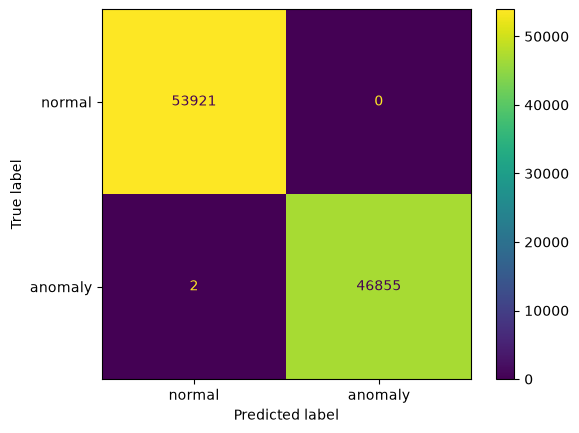

In [46]:
# Datos de entrenamiento
evaluate_classifier(y_tree_train_pred, y_train, clf_tree, f1_score)

f1_score: 0.9983013419398675
Matriz de confusión


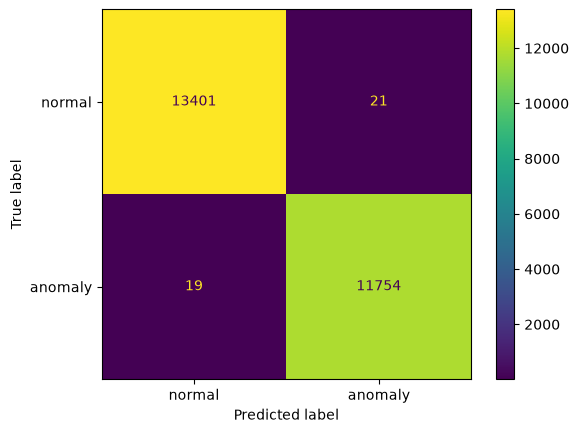

In [47]:
# Datos de prueba
evaluate_classifier(y_tree_test_pred, y_test, clf_tree, f1_score)

### Regresión Logística

f1_score: 0.914356386879289
Matriz de confusión


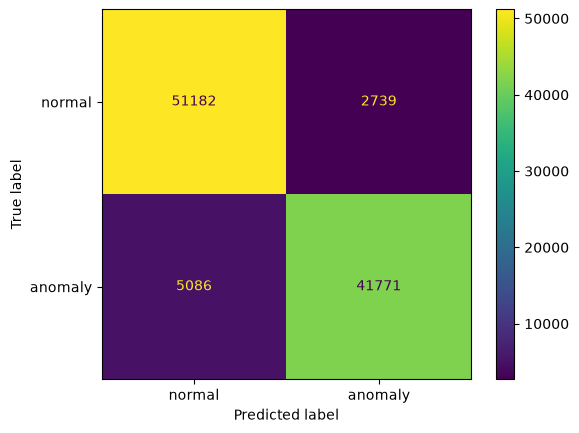

In [48]:
# Datos de entrenamiento
evaluate_classifier(y_lr_train_pred, y_train, clf, f1_score)

f1_score: 0.9142981881685222
Matriz de confusión


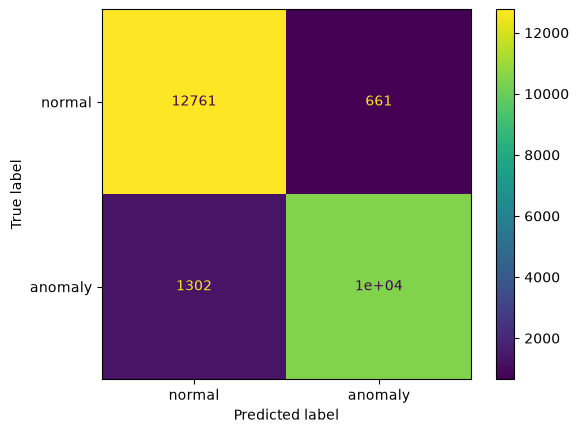

In [49]:
# Datos de prueba
evaluate_classifier(y_lr_test_pred, y_test, clf, f1_score)

Tras evaluar los modelos se ha podido comprobar como el algoritmo de árboles de decisión produce mejores resultados que los de la regresión logística, esto se debe prinicpalmente a que la regresión logística es un algoritmo mucho más rígido pues se basa en una recta y un umbral mientras que los árboles de decisión son más flexibles y tienen en consideración más casuísticas al realizar múltiples divisiones de las variables en busca de un corte óptimo.

Dicho de otra forma, la regresión logística se adecúa bien a los conjuntos de datos que tienen relaciones lineales de tal manera que al trazar una línea se separen los datos de manera más o menos acertada, mientras que los árboles de decisión capturan mejor distribuciones distintas de datos e interacciones entre las características además de ser más resistentes a *outliers*.